# 01 EDA: PSL chase win probability

**Question:** given the match state at any ball of a PSL second innings, what is the probability that the chasing team wins?

Rules followed here:
- EDA uses the **training seasons only** (2015/16 to 2022/23), so nothing we learn here leaks from validation or test.
- Every modelling decision is tied to a pattern in the data. The decision table at the end feeds `src/features.py` and `src/psl_pipeline.py`.

Data: one row per second-innings ball (`data/processed/ball_states.csv`), built by `src/build_dataset.py` from Cricsheet plus Open-Meteo.

In [1]:
import os, pathlib, sys
if pathlib.Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_selection import mutual_info_classif

from psl_pipeline import split_by_season

FIG = pathlib.Path("reports/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("data/processed/ball_states.csv", parse_dates=["date"])
parts, seasons = split_by_season(df)
for k, v in parts.items():
    print(f"{k:5s} {seasons[k]}  matches={v.match_id.nunique()}  rows={len(v)}")
tr = parts["train"]
m = tr.drop_duplicates("match_id")          # one row per match, for match-level facts
print("\nAll columns:", df.shape[1], list(df.columns))

train ['2015/16', '2016/17', '2017/18', '2018/19', '2019/20', '2020/21', '2021', '2021/22', '2022/23']  matches=234  rows=26900
val   ['2023/24', '2025']  matches=63  rows=7222
test  ['2026']  matches=42  rows=4668

All columns: 31 ['match_id', 'date', 'season', 'venue', 'city', 'batting_team', 'bowling_team', 'toss_decision', 'toss_winner_is_chaser', 'in_pakistan', 'first_innings_total', 'target', 'chaser_won', 'legal_balls', 'runs', 'wickets', 'runs_last12', 'wkts_last12', 'temp_c', 'humidity', 'dew_point_c', 'over', 'ball_in_over', 'balls_left', 'wickets_left', 'runs_needed', 'crr', 'rrr', 'rr_gap', 'is_powerplay', 'is_death']


## 1. Missing values and data types

In [2]:
print(tr.dtypes.value_counts().to_dict())
print("missing cells:", int(tr.isna().sum().sum()))

{dtype('int64'): 18, <StringDtype(na_value=nan)>: 6, dtype('float64'): 6, dtype('<M8[us]'): 1}
missing cells: 0


No missing values: the build drops no-result, tie and revised-target matches, and weather covers every city. We still keep `SimpleImputer` in the pipeline, because the deployed API could receive incomplete input and an imputer is cheap insurance.

## 2. Class balance

ball-level: 0.548  match-level: 0.564


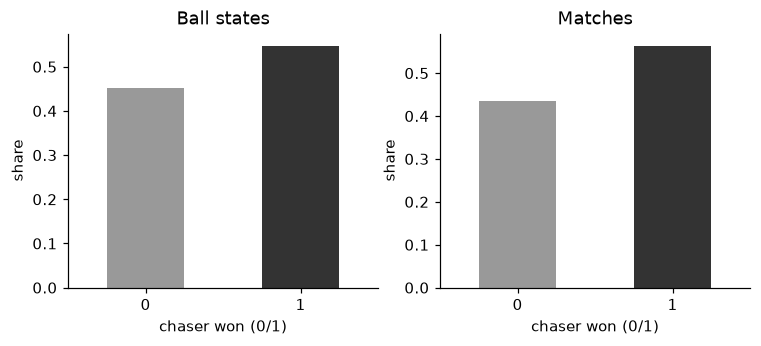

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))
tr["chaser_won"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[0], color=["#999", "#333"], title="Ball states")
m["chaser_won"].value_counts(normalize=True).sort_index().plot.bar(ax=ax[1], color=["#999", "#333"], title="Matches")
for a in ax:
    a.set(xlabel="chaser won (0/1)", ylabel="share"); a.tick_params(axis="x", rotation=0)
fig.savefig(FIG / "eda_1_class_balance.png", bbox_inches="tight")
print("ball-level:", tr.chaser_won.mean().round(3), " match-level:", m.chaser_won.mean().round(3))

**Pattern:** chasers win about 55% of balls and 56% of matches. The classes are close to balanced.
**Decision:** no resampling or class weights. Use **ROC-AUC** (ranking quality, threshold-free) as the tuning metric, and report F1, accuracy and log loss. Log loss matters because the app shows a probability.

## 3. Required run rate: distribution and outliers

{0.5: 9.0, 0.9: 14.2, 0.99: 42.0, 0.999: 162.6, 1.0: 408.0}


rows with RRR > 36: 338, chaser win rate among them: 0.00


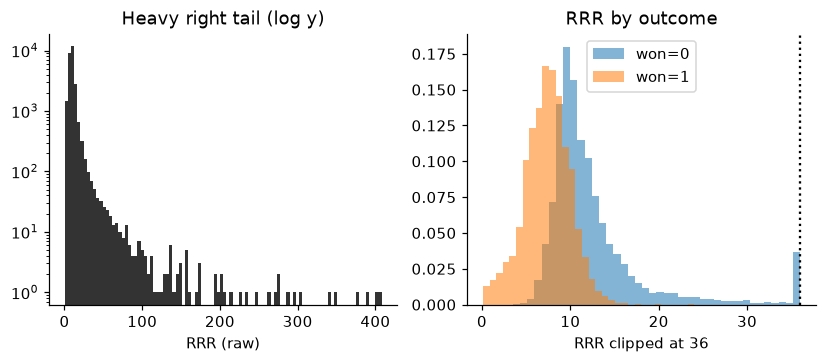

In [4]:
print(tr["rrr"].quantile([.5, .9, .99, .999, 1]).round(1).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].hist(tr["rrr"], bins=100, color="#333"); ax[0].set(yscale="log", xlabel="RRR (raw)", title="Heavy right tail (log y)")
for k, g in tr.groupby("chaser_won"):
    ax[1].hist(g["rrr"].clip(upper=36), bins=40, alpha=.55, density=True, label=f"won={k}")
ax[1].axvline(36, color="k", ls=":"); ax[1].set(xlabel="RRR clipped at 36", title="RRR by outcome"); ax[1].legend()
fig.savefig(FIG / "eda_2_rrr.png", bbox_inches="tight")
hi = tr[tr.rrr > 36]
print(f"rows with RRR > 36: {len(hi)}, chaser win rate among them: {hi.chaser_won.mean():.2f}")

**Pattern:** RRR has a very heavy tail (median 9, max above 400, skew about 16), from the last balls of hopeless chases. Above 36 (six off every ball) the chaser **never** wins in training.
**Decision:** clip `rrr` (and `crr`, which spikes in the first balls) at **36**. The meaning is unchanged, since anything above 36 is a lost cause. The clip stops a few extreme values from dominating the scaled features for logistic regression and KNN. RRR clearly separates the classes, so it is also the **baseline** model's only feature.

## 4. Wickets lost vs win rate

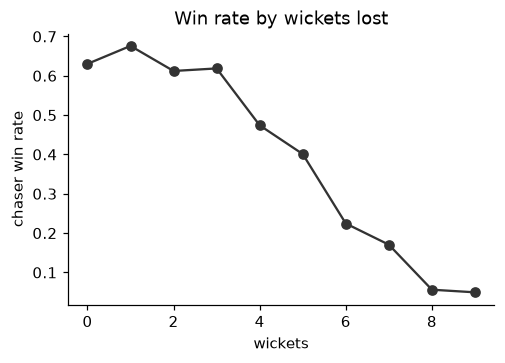

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.2))
tr.groupby("wickets")["chaser_won"].mean().plot(marker="o", color="#333", ax=ax)
ax.set(ylabel="chaser win rate", title="Win rate by wickets lost")
fig.savefig(FIG / "eda_3_wickets.png", bbox_inches="tight")

**Pattern:** win rate holds at about 0.6 up to 3 wickets, then falls steeply (0.47 at 4, 0.05 at 9). The effect is strong and **non-linear**.
**Decision:** keep `wickets`. Its non-linearity is one reason to compare tree models (RF, boosting) against logistic regression.

## 5. Venue effect

                                     matches  avg_first_innings  \
venue                                                             
Dubai International Cricket Stadium       57             148.30   
Sharjah Cricket Stadium                   35             153.74   
Sheikh Zayed Stadium, Abu Dhabi           24             167.29   
Multan Cricket Stadium                     8             173.62   
National Stadium, Karachi                 58             173.78   
Gaddafi Stadium, Lahore                   38             177.05   
Rawalpindi Cricket Stadium                14             201.64   

                                     chase_win_rate  
venue                                                
Dubai International Cricket Stadium            0.67  
Sharjah Cricket Stadium                        0.69  
Sheikh Zayed Stadium, Abu Dhabi                0.46  
Multan Cricket Stadium                         0.25  
National Stadium, Karachi                      0.60  
Gaddafi Stadium, L

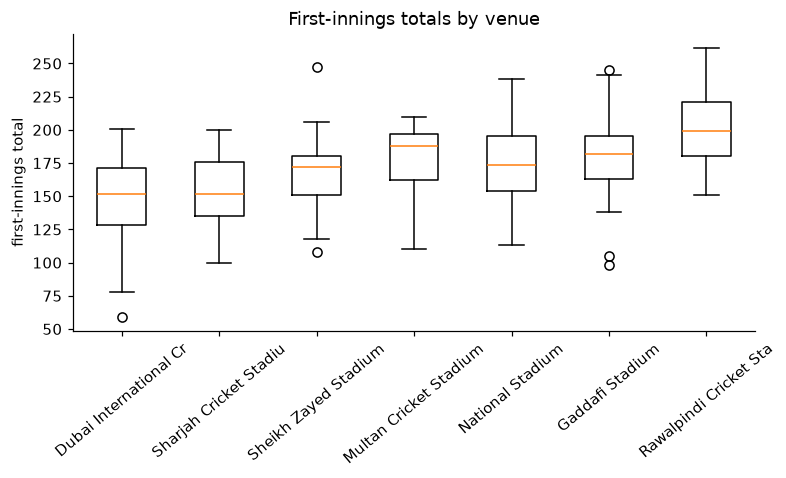

In [6]:
v = m.groupby("venue").agg(matches=("match_id", "size"), avg_first_innings=("first_innings_total", "mean"),
                           chase_win_rate=("chaser_won", "mean")).round(2).sort_values("avg_first_innings")
print(v)
fig, ax = plt.subplots(figsize=(8, 3.5))
order = v.index
ax.boxplot([m.loc[m.venue == x, "first_innings_total"] for x in order], tick_labels=[x.split(",")[0][:22] for x in order])
ax.tick_params(axis="x", rotation=40); ax.set(ylabel="first-innings total", title="First-innings totals by venue")
fig.savefig(FIG / "eda_4_venue.png", bbox_inches="tight")

**Pattern:** average first-innings totals range from about 148 (Dubai) to about 202 (Rawalpindi), a gap larger than one standard deviation (32 runs). Chase win rates also differ (Sharjah 0.69, Lahore 0.34). A target of 170 means different things at different grounds.
**Decision:** keep `venue` (one-hot, 7 grounds) and `venue_avg_first`, learned inside the pipeline from training folds only (`VenueAverage`). `in_pakistan` is fully determined by venue, so it is dropped as redundant.

## 6. Correlation and redundancy

,feature A,feature B,r
0,over,runs,0.933
1,over,balls_left,-0.999
2,over,runs_needed,-0.830
3,over,is_powerplay,-0.804
4,runs,balls_left,-0.934
5,wickets,wickets_left,-1.000
6,balls_left,runs_needed,0.831
7,balls_left,is_powerplay,0.803
8,rrr,rr_gap,-0.975


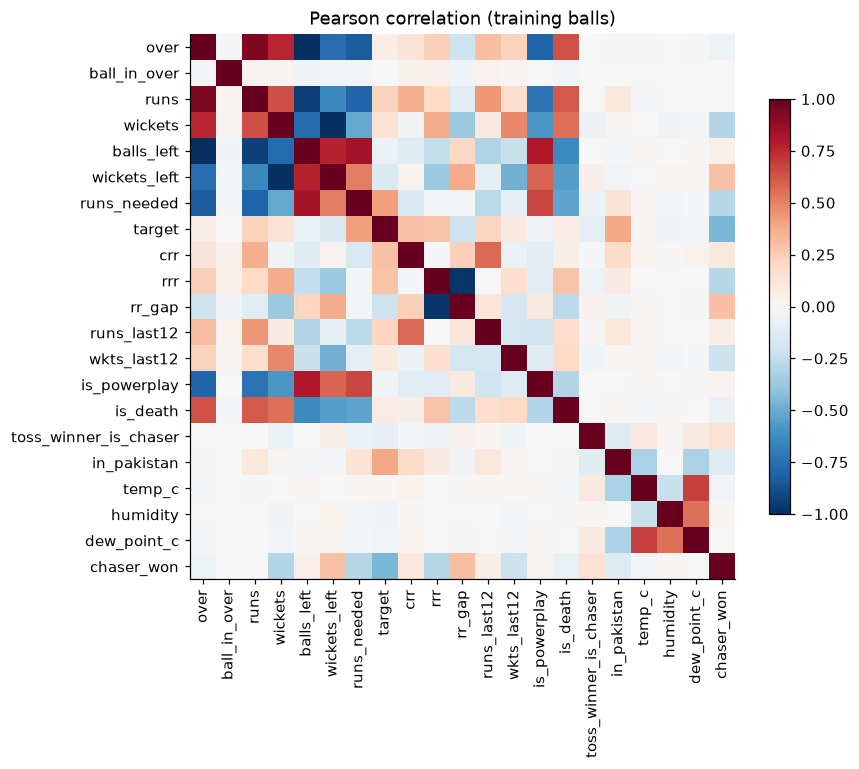

In [7]:
num = ["over", "ball_in_over", "runs", "wickets", "balls_left", "wickets_left", "runs_needed", "target", "crr", "rrr",
       "rr_gap", "runs_last12", "wkts_last12", "is_powerplay", "is_death", "toss_winner_is_chaser", "in_pakistan",
       "temp_c", "humidity", "dew_point_c"]
corr = tr[num + ["chaser_won"]].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90); ax.set_yticks(range(len(corr)), corr.columns)
fig.colorbar(im, ax=ax, shrink=.7); ax.set_title("Pearson correlation (training balls)")
fig.savefig(FIG / "eda_5_correlation.png", bbox_inches="tight")
pairs = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(num) for b in num[i + 1:] if abs(corr.loc[a, b]) > .8]
pd.DataFrame(pairs, columns=["feature A", "feature B", "r"])

**Pattern:** several features are near-copies of each other.
- `wickets_left` = 10 - `wickets` (r = -1).
- `over` and `balls_left` (r = -0.999); `ball_in_over` adds nothing on top.
- `rr_gap` = `crr` - `rrr` (r = -0.975 with `rrr`).
- `runs` = `target` - `runs_needed`.
- `is_powerplay` and `is_death` are coarse bins of `balls_left`.

**Decision:** keep one feature from each group: `balls_left`, `wickets`, `runs_needed`, `target`, `rrr`, `crr`. Duplicates add no information. They make logistic regression coefficients unstable and give KNN distances double weight, and every extra feature is one more thing to explain.

## 7. Weather (second data source): real signal or match identity?

,ball-level mutual information,match-level correlation with win
temp_c,0.497,-0.031
humidity,0.405,0.025
dew_point_c,0.497,-0.003


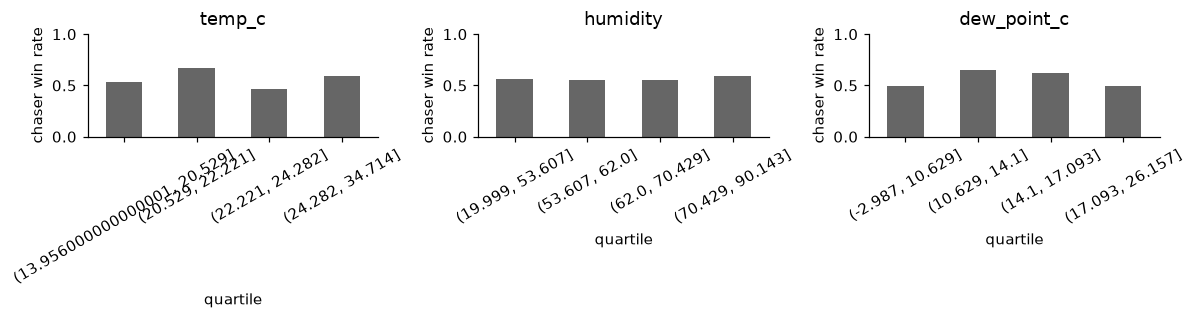

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a, c in zip(ax, ["temp_c", "humidity", "dew_point_c"]):
    q = pd.qcut(m[c], 4)
    m.groupby(q, observed=True)["chaser_won"].mean().plot.bar(ax=a, color="#666")
    a.set(title=c, xlabel="quartile", ylabel="chaser win rate", ylim=(0, 1)); a.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(FIG / "eda_6_weather.png", bbox_inches="tight")

w = ["temp_c", "humidity", "dew_point_c"]
ball_mi = mutual_info_classif(tr[w], tr.chaser_won, random_state=0)
match_r = m[w + ["chaser_won"]].corr()["chaser_won"][w]
pd.DataFrame({"ball-level mutual information": ball_mi.round(3), "match-level correlation with win": match_r.round(3)}, index=w)

**Pattern:** at match level, weather is almost unrelated to the result (|r| < 0.03, quartile win rates go up and down with no trend). Yet at ball level its mutual information looks **higher than any match-state feature**.

That is a trap. Each match has its own unique weather value shared by about 115 rows with the same label, so weather works like a **match ID**. A flexible model can memorize matches through it, which looks good in training and fails on new matches.

**Decision:** keep **`dew_point_c` only**. Dew is the one weather effect cricket has a reason to expect (a wet ball is harder to grip, which helps the chasing side at night), and grouped CV shows the smallest cost for it (section 10). Drop `temp_c` and `humidity`. All three stay in the dataset, and CV by match (`GroupKFold`) protects the evaluation from this memorization.

## 8. Team identity over seasons

teams only in test season: {'Hyderabad Kingsmen', 'Rawalpindiz'}


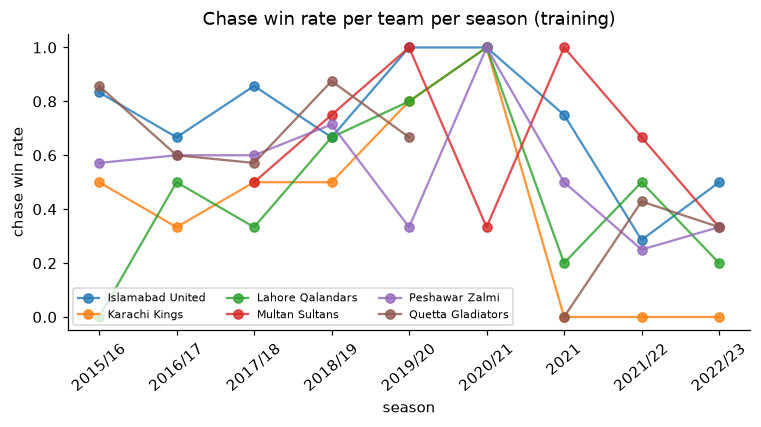

In [9]:
t = m.groupby(["season", "batting_team"])["chaser_won"].mean().unstack()
fig, ax = plt.subplots(figsize=(8, 3.5))
t.plot(marker="o", ax=ax, alpha=.8); ax.set(ylabel="chase win rate", title="Chase win rate per team per season (training)")
ax.legend(fontsize=7, ncol=3); ax.tick_params(axis="x", rotation=40)
fig.savefig(FIG / "eda_7_teams.png", bbox_inches="tight")
print("teams only in test season:", set(parts["test"].batting_team) - set(tr.batting_team))

**Pattern:** a team's chase win rate swings from 0 to 1 between seasons, because squads change every year through the draft. The **test season (2026) has two new franchises** (Hyderabad Kingsmen, Rawalpindiz) that never appear in training.
**Decision:** drop `batting_team` and `bowling_team`. Team names carry no stable signal and cannot generalize to new teams. The app can still ask for team names for display.

## 9. Toss

In [10]:
print(pd.crosstab(m.toss_decision, m.toss_winner_is_chaser))
print(m.groupby("toss_winner_is_chaser")["chaser_won"].agg(["mean", "size"]).round(3))

toss_winner_is_chaser   0    1
toss_decision                 
bat                    50    0
field                   0  184
                        mean  size
toss_winner_is_chaser             
0                      0.420    50
1                      0.603   184


**Pattern:** `toss_decision == "field"` happens exactly when the toss winner is the chaser, so the two columns hold the same information. Chasers who won the toss win 60% of matches, against 42% otherwise (match-level r = 0.15).
**Decision:** keep `toss_winner_is_chaser`, drop `toss_decision` (duplicate).

## 10. Checking the decisions with grouped cross-validation (training seasons only)

In [11]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GroupKFold, cross_val_score
from psl_pipeline import make_pipeline

d = tr.assign(rrr=tr.rrr.clip(upper=36), crr=tr.crr.clip(upper=36))
lean = ["balls_left", "runs_needed", "wickets", "target", "rrr", "crr", "runs_last12", "wkts_last12",
        "toss_winner_is_chaser", "venue_avg_first"]
all_num = num[:17] + ["venue_avg_first"]
sets = {"all 25 features": (all_num + w, ["batting_team", "bowling_team", "venue", "toss_decision"]),
        "lean": (lean, ["venue"]), "lean + 3 weather": (lean + w, ["venue"]),
        "lean + dew (chosen)": (lean + ["dew_point_c"], ["venue"]),
        "lean + teams": (lean, ["venue", "batting_team", "bowling_team"])}
rows = []
for name, (n, c) in sets.items():
    cols = ["match_id"] + [x for x in n if x != "venue_avg_first"] + c + ([] if "target" in n else ["target"])
    for mname, clf in [("logreg", LogisticRegression(max_iter=2000)),
                       ("hist_gb", HistGradientBoostingClassifier(max_depth=3, learning_rate=.06, random_state=0))]:
        s = cross_val_score(make_pipeline(clf, n, c), d[cols], d.chaser_won, groups=d.match_id,
                            cv=GroupKFold(5), scoring="roc_auc")
        rows.append({"features": name, "model": mname, "cv_roc_auc": s.mean().round(3)})
pd.DataFrame(rows).pivot(index="features", columns="model", values="cv_roc_auc")

model,hist_gb,logreg
features,,
all 25 features,0.825,0.866
lean,0.873,0.894
lean + 3 weather,0.839,0.883
lean + dew (chosen),0.849,0.890
lean + teams,0.860,0.880


**Pattern:** the lean set beats "all features" for both models. Adding all three weather columns or the team names makes CV AUC **worse**, which confirms the memorization and drift seen above. Dew alone costs very little.

## Decision table (input to Batch 3)

| # | Pattern in training data | Decision |
|---|---|---|
| 1 | No missing values | Keep `SimpleImputer` as insurance for API input |
| 2 | Classes about 55/45 | No resampling. Tune on ROC-AUC; also report F1, accuracy, log loss |
| 3 | RRR and CRR heavy tails; chaser never wins with RRR > 36 | Clip `rrr` and `crr` at 36. RRR-only baseline |
| 4 | Wickets: strong, non-linear effect | Keep `wickets`; compare tree models with linear ones |
| 5 | Venue average totals 148 to 202; chase win rate varies by ground | Keep `venue` one-hot plus fold-safe `venue_avg_first`; drop `in_pakistan` (implied by venue) |
| 6 | Near-duplicate features (r > 0.97) | Drop `wickets_left`, `over`, `ball_in_over`, `rr_gap`, `runs`, `is_powerplay`, `is_death` |
| 7 | Weather: no match-level signal; acts as a match ID | Keep `dew_point_c` only (domain reason); drop `temp_c`, `humidity` |
| 8 | Team form swings by season; 2 unseen teams in test | Drop `batting_team`, `bowling_team` |
| 9 | `toss_decision` duplicates `toss_winner_is_chaser` | Keep `toss_winner_is_chaser` only |

**Final model inputs (12):** `balls_left`, `runs_needed`, `wickets`, `target`, `rrr`, `crr`, `runs_last12`, `wkts_last12`, `toss_winner_is_chaser`, `dew_point_c`, `venue_avg_first` (numeric) and `venue` (categorical). The dataset has 25 candidate features; these 12 are the subset the evidence supports.